# ML6 - Customer Segmentation

In [1]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

In [2]:
train = pd.read_csv("../data/processed/train.csv")

customer_ids = train["Customer ID"].unique()
product_codes = train["StockCode"].unique()

customer_map = {customer: i for i, customer in enumerate(customer_ids)}
product_map = {product: j for j, product in enumerate(product_codes)}

rows = train["Customer ID"].map(customer_map)
cols = train["StockCode"].map(product_map)
values = np.log1p(train["Quantity"])

A = sp.csr_matrix(
    (values, (rows, cols)),
    shape=(len(customer_map), len(product_map))
)

svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

customer_factors = svd.fit_transform(A)

print(customer_factors.shape)

(5484, 100)


## Customer Clustering


In [3]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(customer_factors)

print("Cluster sizes:")

unique, counts = np.unique(clusters, return_counts=True)

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count} customers")

Cluster sizes:
Cluster 0: 5389 customers
Cluster 1: 89 customers
Cluster 2: 5 customers
Cluster 3: 1 customers


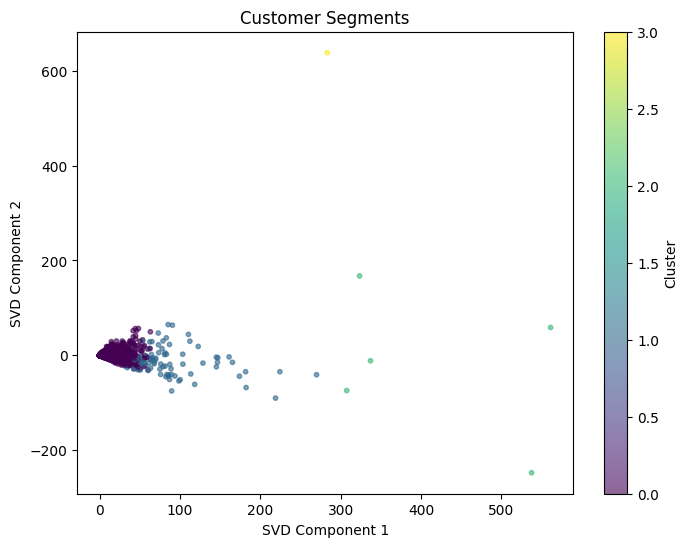

In [4]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    customer_factors[:, 0],
    customer_factors[:, 1],
    c=clusters,
    s=10,
    alpha=0.6
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Customer Segments")
plt.colorbar(scatter, label="Cluster")
plt.show()

## Normalize Customer Representations

In [5]:
from sklearn.preprocessing import normalize

customer_factors_normalized = normalize(customer_factors)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(customer_factors_normalized)

unique, counts = np.unique(clusters, return_counts=True)

print("Cluster sizes:")

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count} customers")

Cluster sizes:
Cluster 0: 2419 customers
Cluster 1: 1532 customers
Cluster 2: 702 customers
Cluster 3: 831 customers


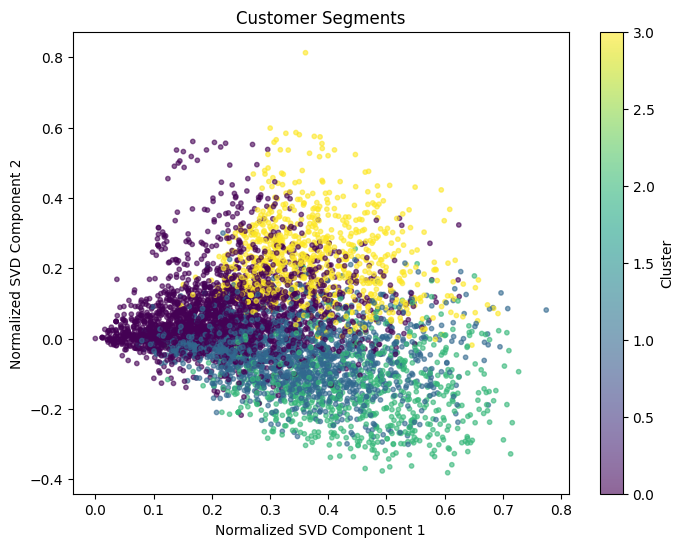

In [6]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    customer_factors_normalized[:, 0],
    customer_factors_normalized[:, 1],
    c=clusters,
    s=10,
    alpha=0.6
)

plt.xlabel("Normalized SVD Component 1")
plt.ylabel("Normalized SVD Component 2")
plt.title("Customer Segments")
plt.colorbar(scatter, label="Cluster")

plt.show()

## Describe Customer Segments


In [ ]:
customer_cluster_df = pd.DataFrame({
    "Customer ID": customer_ids,
    "Cluster": clusters
})


In [8]:
train_with_clusters = train.merge(
    customer_cluster_df,
    on="Customer ID",
    how="left"
)

In [9]:
for cluster in sorted(train_with_clusters["Cluster"].unique()):
    cluster_data = train_with_clusters[
        train_with_clusters["Cluster"] == cluster
    ]

    print(f"\n--- Cluster {cluster} ---")

    print("\nTop products:")
    top_products = (
        cluster_data.groupby(["StockCode", "Description"])["Quantity"]
        .sum()
        .sort_values(ascending=False)
        .head(5)
    )
    print(top_products)

    print("\nTop countries:")
    top_countries = (
        cluster_data["Country"]
        .value_counts()
        .head(5)
    )
    print(top_countries)


--- Cluster 0 ---

Top products:
StockCode  Description                       
23166      MEDIUM CERAMIC TOP STORAGE JAR        75170
84879      ASSORTED COLOUR BIRD ORNAMENT         29585
37410      BLACK AND WHITE PAISLEY FLOWER MUG    25654
16014      SMALL CHINESE STYLE SCISSOR           24760
21982      PACK OF 12 SUKI TISSUES               22632
Name: Quantity, dtype: int64

Top countries:
Country
United Kingdom    170170
Germany             1500
France               494
Poland               420
Greece               387
Name: count, dtype: int64

--- Cluster 1 ---

Top products:
StockCode  Description                       
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     77130
21977      PACK OF 60 PINK PAISLEY CAKE CASES    35280
84991      60 TEATIME FAIRY CAKE CASES           34330
22492      MINI PAINT SET VINTAGE                31795
21915      RED  HARMONICA IN BOX                 28594
Name: Quantity, dtype: int64

Top countries:
Country
United Kingdom    172982
EIRE    

##  Cluster 0: Home & Utility
##  Cluster 1: Novelty & Party
##  Cluster 2: Bags & Storage
##  Cluster 3: Decorative Homeware

In [10]:
segment_summary = pd.DataFrame({
    "Cluster": [0, 1, 2, 3],
    "Segment Name": [
        "Home & Utility",
        "Novelty & Party",
        "Bags & Storage",
        "Decorative Homeware"
    ],
    "Customers": [2419, 1532, 702, 831]
})

segment_summary

,Cluster,Segment Name,Customers
0,0,Home & Utility,2419
1,1,Novelty & Party,1532
2,2,Bags & Storage,702
3,3,Decorative Homeware,831
